## H&M EDA Analysis

In [45]:
import pandas as pd 
import numpy as np
import os 
import matplotlib.pyplot as plt

In [28]:
# Reading in the customer.csv dataset
customer_df = pd.read_csv('customers.csv')
customer_df.head(10)

,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.0,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.0,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.0,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.0,1.0,ACTIVE,Regularly,52.0,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...
5,000064249685c11552da43ef22a5030f35a147f723d5b0...,NaN,NaN,NaN,NaN,NaN,2c29ae653a9282cce4151bd87643c907644e09541abc28...
6,0000757967448a6cb83efb3ea7a3fb9d418ac7adf2379d...,NaN,NaN,ACTIVE,NONE,20.0,fe7b8e2b3fafb89ca90db17ffeeae0fd29b795d803f749...
7,00007d2de826758b65a93dd24ce629ed66842531df6699...,1.0,1.0,ACTIVE,Regularly,32.0,8d6f45050876d059c830a0fe63f1a4c022de279bb68ce3...
8,00007e8d4e54114b5b2a9b51586325a8d0fa74ea23ef77...,NaN,NaN,ACTIVE,NONE,20.0,2c29ae653a9282cce4151bd87643c907644e09541abc28...
9,00008469a21b50b3d147c97135e25b4201a8c58997f787...,NaN,NaN,ACTIVE,NONE,20.0,2c29ae653a9282cce4151bd87643c907644e09541abc28...


In [29]:
print(customer_df.shape)
print(customer_df.isnull().sum())

(1371980, 7)
customer_id                    0
FN                        895050
Active                    907576
club_member_status          6062
fashion_news_frequency     16011
age                        15861
postal_code                    0
dtype: int64


In [30]:
cols = [
    "FN",
    "Active",
    "club_member_status",
    "fashion_news_frequency"
]

for col in cols:
    print(f"\n{col}")
    print(customer_df[col].value_counts(dropna=False))


FN
FN
NaN    895050
1.0    476930
Name: count, dtype: int64

Active
Active
NaN    907576
1.0    464404
Name: count, dtype: int64

club_member_status
club_member_status
ACTIVE        1272491
PRE-CREATE      92960
NaN              6062
LEFT CLUB         467
Name: count, dtype: int64

fashion_news_frequency
fashion_news_frequency
NONE         877711
Regularly    477416
NaN           16011
Monthly         842
Name: count, dtype: int64


In [31]:
pd.crosstab(
    customer_df["FN"].isna(),
    customer_df["Active"].isna()
)

Active,False,True
FN,,
False,464404,12526
True,0,895050


In [32]:
pd.crosstab(
    customer_df["club_member_status"].fillna("Unknown"),
    customer_df["FN"].isna(),
    normalize="index"
).round(3)

FN,False,True
club_member_status,,
ACTIVE,0.370,0.630
LEFT CLUB,0.017,0.983
PRE-CREATE,0.062,0.938
Unknown,0.053,0.947


In [33]:
# Reading in the transactions dataset
transactions_df = pd.read_csv('transactions_train.csv')
transactions_df.head(5)

,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2


## Customer features (simple RFM segmentation)
One row per customer: Recency, Frequency, Monetary, plus average basket value and online share.

In [34]:
# Collapse transactions to one row per (customer, purchase day), reading the big file in chunks
cust_index = pd.Index(customer_df['customer_id'])

parts = []
reader = pd.read_csv(
    'transactions_train.csv',
    usecols=['t_dat', 'customer_id', 'price', 'sales_channel_id'],
    dtype={'t_dat': 'string', 'customer_id': 'string', 'price': 'float32', 'sales_channel_id': 'int8'},
    chunksize=2_000_000,
)
for chunk in reader:
    chunk['cid'] = cust_index.get_indexer(chunk['customer_id'])
    chunk['online'] = chunk['sales_channel_id'] == 2
    parts.append(
        chunk.groupby(['cid', 't_dat'])
             .agg(spend=('price', 'sum'), n_online=('online', 'sum'), n_items=('price', 'size'))
             .reset_index()
    )

# a basket can straddle two chunks, so merge duplicates
baskets = pd.concat(parts).groupby(['cid', 't_dat'], as_index=False).sum()
baskets['t_dat'] = pd.to_datetime(baskets['t_dat'])
print(baskets.shape)

(9080179, 5)


In [ ]:
cutoff = baskets['t_dat'].max()

customer_features = baskets.groupby('cid').agg(
    last_purchase=('t_dat', 'max'),
    frequency=('t_dat', 'size'),          # number of purchase days
    monetary=('spend', 'sum'),
    n_items=('n_items', 'sum'),
    n_online=('n_online', 'sum'),
)
customer_features['recency'] = (cutoff - customer_features['last_purchase']).dt.days
customer_features['avg_basket_value'] = customer_features['monetary'] / customer_features['frequency']
customer_features['online_share'] = customer_features['n_online'] / customer_features['n_items']

customer_features = customer_features[['recency', 'frequency', 'monetary', 'avg_basket_value', 'online_share']]
# Using customer cid to map back to the original customer index
customer_features.index = cust_index[customer_features.index]
customer_features.index.name = 'customer_id'
customer_features = customer_features.reset_index()

print(f"{len(customer_features):,} customers with purchases (of {len(customer_df):,})")
customer_features.describe().T.round(3)

1,362,281 customers with purchases (of 1,371,980)


,count,mean,std,min,25%,50%,75%,max
recency,1362281.0,235.148,221.119,0.000,48.000,151.000,398.000,733.000
frequency,1362281.0,6.665,9.707,1.000,1.000,3.000,8.000,427.000
monetary,1362281.0,0.649,1.198,0.001,0.088,0.246,0.701,57.676
avg_basket_value,1362281.0,0.096,0.086,0.001,0.047,0.073,0.117,22.480
online_share,1362281.0,0.663,0.405,0.000,0.256,0.914,1.000,1.000


In [36]:
customer_features.to_csv('customer_features.csv', index=False)
customer_features.head()

,customer_id,recency,frequency,monetary,avg_basket_value,online_share
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,17,10,0.648983,0.064898,0.571429
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,76,23,2.601932,0.113127,0.941860
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,7,7,0.704780,0.100683,1.000000
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,471,1,0.060983,0.060983,1.000000
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,41,6,0.469695,0.078282,0.846154


In [52]:
# Reading in customer feature data again
customer_features = pd.read_csv('customer_features.csv')
print(customer_features.shape)
customer_features.head(5)

(1362281, 6)


,customer_id,recency,frequency,monetary,avg_basket_value,online_share
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,17,10,0.648983,0.064898,0.571429
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,76,23,2.601932,0.113127,0.941860
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,7,7,0.704780,0.100683,1.000000
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,471,1,0.060983,0.060983,1.000000
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,41,6,0.469695,0.078282,0.846154


## Next steps for segmentation

1. **Check the distributions.** Plot histograms of the five features. Expect `frequency`, `monetary` and `avg_basket_value` to be heavily right-skewed.
2. **Handle skew and scale.** Apply `np.log1p` to the skewed columns, then standardize (`StandardScaler`) so no feature dominates the distance calculation.
3. **Decide who to cluster.** One-time buyers have no real frequency signal. Decide whether to cluster everyone or set them aside as their own "one-and-done" group.
4. **Choose k.** Try k-means for k = 2 to 10. Compare the elbow plot and silhouette score (on a sample, since there are over a million customers).
5. **Profile the segments.** Take the mean of each original feature per cluster, plus cluster size. Give each segment a plain-English name (e.g. loyal high-spenders, lapsed, online-first).
6. **Sanity-check stability.** Re-run with different random seeds or samples. Do the segments stay roughly the same?
7. **Enrich later (optional).** Add `age` and club status from `customers.csv`, and product mix from `articles.csv`, to describe the segments, not to build them.

### Split one-time buyers from repeat customers
About 33% of customers have `frequency == 1`. Their frequency carries no signal, so cluster repeat buyers only and handle one-time buyers separately.

In [53]:
one_time = customer_features[customer_features['frequency'] == 1].copy()
repeat = customer_features[customer_features['frequency'] >= 2].copy()
print(f"one-time: {len(one_time):,} | repeat: {len(repeat):,}")

# one-time buyers: a simple recency split instead of clustering
one_time['segment'] = pd.cut(
    one_time['recency'], bins=[-1, 90, 365, np.inf],
    labels=['one-time: recent (<=90d)', 'one-time: cooling (91-365d)', 'one-time: lapsed (>365d)'])
one_time['segment'].value_counts()

one-time: 447,973 | repeat: 914,308


segment
one-time: lapsed (>365d)       236600
one-time: cooling (91-365d)    154450
one-time: recent (<=90d)        56923
Name: count, dtype: int64

### Distributions of repeat customers

In [54]:
features = ['recency', 'frequency', 'monetary', 'avg_basket_value', 'online_share']
repeat[features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
recency,914308.0,160.147,173.183,0.000,30.000,88.000,241.000,732.000
frequency,914308.0,9.441,10.815,2.000,3.000,6.000,12.000,427.000
monetary,914308.0,0.921,1.381,0.003,0.218,0.474,1.058,57.676
avg_basket_value,914308.0,0.097,0.074,0.002,0.051,0.076,0.118,3.245
online_share,914308.0,0.641,0.377,0.000,0.308,0.778,1.000,1.000


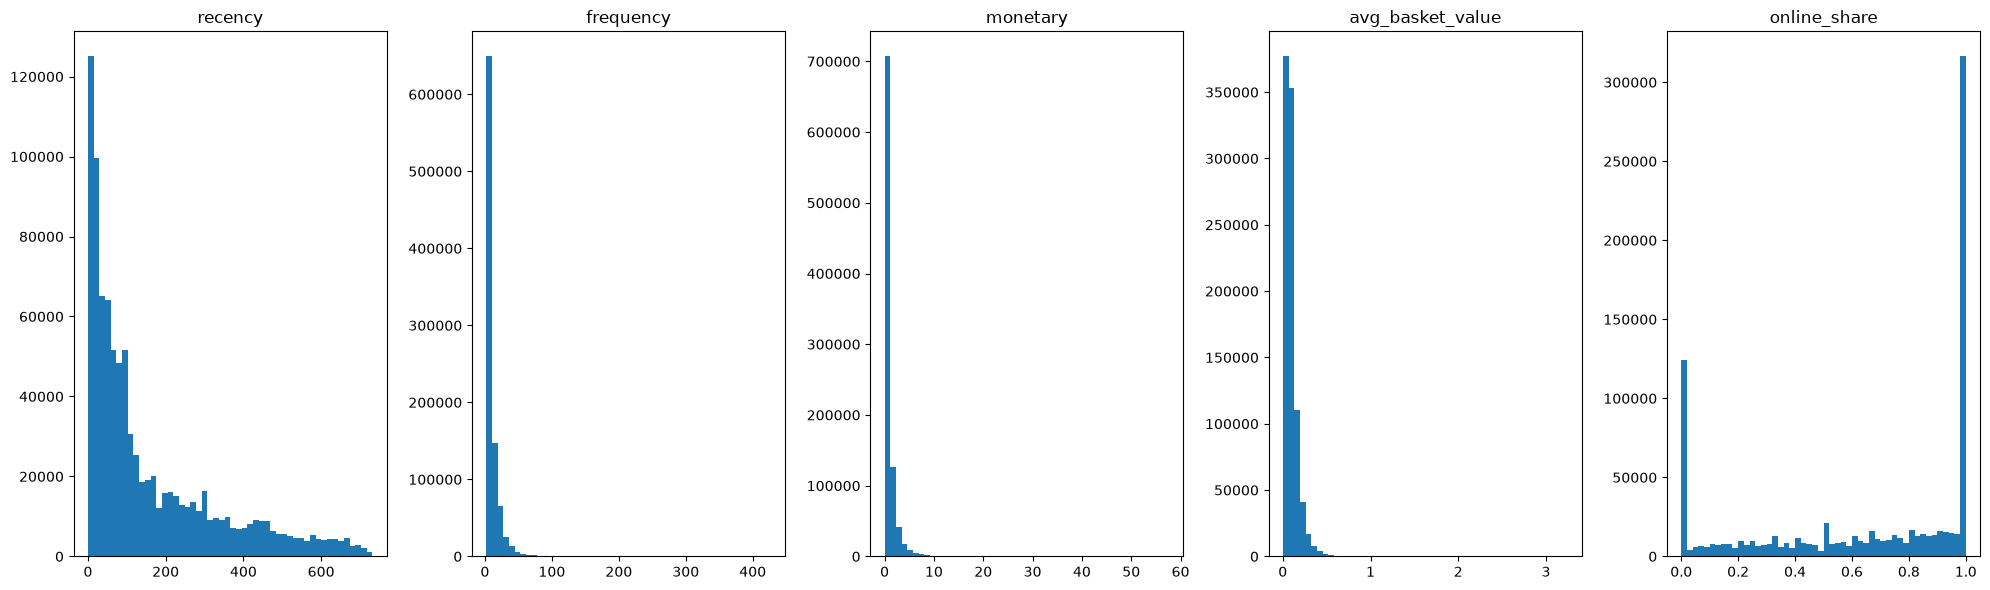

In [55]:
fig, axes = plt.subplots(1, 5, figsize=(20, 6))
for ax, col in zip(axes, features):
    ax.hist(repeat[col], bins=50)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [56]:
# skewness: values well above 1 mean a long right tail, so log-transform before clustering
repeat[features].skew().round(2)

recency             1.35
frequency           4.13
monetary            5.53
avg_basket_value    3.41
online_share       -0.59
dtype: float64

### Why `log1p` for some columns and `log` for others! Important to take note...:/
- **`recency` -> `log1p`:** it can be exactly 0 (bought on the last day), and `log(0)` is undefined. The +1 avoids that.
- **`frequency` -> `log1p`:** the minimum is 2, so plain `log` would work. `log1p` is the usual convention for counts and keeps it consistent with `recency`.
- **`monetary`, `avg_basket_value` -> `log`:** these are on the normalized price scale (median basket ~0.08) and are always above zero. `log1p` of a tiny number is almost the number itself, so it would barely reshape the bulk of the data. Plain `log` spreads it out properly.
- **`online_share` -> none:** the issue is the spikes at 0 and 1, not skew. Just scale it.

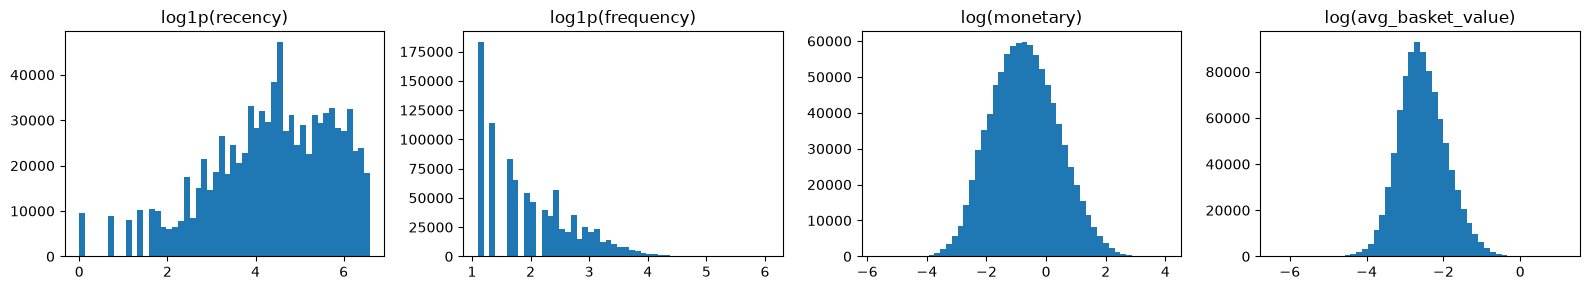

In [57]:
# log-transform check: log1p where 0 is possible / values are >= 1, plain log for the tiny normalized-price columns
log_cols = {'recency': np.log1p, 'frequency': np.log1p, 'monetary': np.log, 'avg_basket_value': np.log}
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, (col, fn) in zip(axes, log_cols.items()):
    ax.hist(fn(repeat[col]), bins=50)
    ax.set_title(f'{fn.__name__}({col})')
plt.tight_layout()
plt.show()

In [58]:
# correlation: highly correlated features double-count the same signal in k-means
repeat[features].corr().round(2)

,recency,frequency,monetary,avg_basket_value,online_share
recency,1.00,-0.37,-0.29,-0.01,-0.01
frequency,-0.37,1.00,0.78,0.01,-0.01
monetary,-0.29,0.78,1.00,0.42,0.16
avg_basket_value,-0.01,0.01,0.42,1.00,0.33
online_share,-0.01,-0.01,0.16,0.33,1.00


## Next steps (after the transforms)

1. **Build the matrix.** Apply `log1p` / `log` to `recency`, `frequency`, `monetary`, `avg_basket_value`, then `StandardScaler` on all five features (`online_share` is just scaled).
2. **Take a sample.** Use ~100k repeat customers for choosing k, to keep it fast.
3. **Choose k.** Fit k-means for k = 2 to 10 and record the inertia (within-cluster sum of squares) for each. Plot inertia against k and look for the elbow, where adding clusters stops helping much. Confirm with the silhouette score on a smaller sample (~10-20k rows).
   - If k-means is still too slow, use `MiniBatchKMeans` (from `sklearn.cluster`). It fits on small random batches of data instead of all rows at once, so it's much faster, with slightly rougher clusters.
4. **Fit the final model.** Re-run k-means with the chosen k on all repeat customers, using a fixed `random_state`.
5. **Profile the segments.** Average the original (untransformed) features per cluster, plus cluster size. Name each segment in plain English.
6. **Check stability.** Re-fit with a different seed or sample. Do the segments stay similar?
7. **Combine.** Put the repeat-customer clusters together with the one-time buyer segments into one segment table.